In [24]:

from pathlib import Path
import sys
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

PROJECT_ROOT = Path.cwd()

while not (PROJECT_ROOT / "src" / "data.py").exists():
    if PROJECT_ROOT.parent == PROJECT_ROOT:
        raise FileNotFoundError("Could not locate src/data.py")
    PROJECT_ROOT = PROJECT_ROOT.parent

sys.path.insert(0, str(PROJECT_ROOT / "src"))

from data import load_data

DATA_DIR = PROJECT_ROOT / "data" / "raw"


# Dataset checks

This notebook checks the raw files before analysis: their shape, missing values, duplicate VM/timestamp keys, CPU ranges, VM coverage, and timestamp spacing. It then builds the timestamp-level mean used by the forecasting pipeline. These checks are exploratory; `src/validation.py` enforces the pipeline requirements.

In [2]:
cpu_readings, vm_metadata = load_data(DATA_DIR)

In [6]:
cpu_readings.head()

,timestamp,vm_id,min_cpu,max_cpu,avg_cpu
0,0,H+FUHUNaeQQvSYHWhak3XW+9PifF0TXQiyYQGEVbDiJoZP...,1.812194,14.587021,4.851659
1,0,pjJUurJZ7RpWz3MS+oYTDl0CBOeltBhkx7g/e1oB5V6wiW...,4.126021,5.650850,4.687886
2,0,iiljldVGhxG8yYxCrv3jGPpNnvhepXkq21OWoaI9RwsN+Q...,1.225669,2.082111,1.607588
3,0,/f+jE9mriEjSsdEzv/qBP0jhMk+EYf9qw928F/sgbwOX2F...,1.939634,3.228830,2.374714
4,0,wClSIZ+AWnTzhVNn/JqFn6WVHZDJ4lJ3aaL2NC8ZqNfUlu...,0.352236,0.855003,0.597535


In [7]:
vm_metadata.head()

,vm_id,subscription_id,deployment_id,timestamp_vm_created,timestamp_vm_deleted,max_cpu,avg_cpu,p95_max_cpu,vm_category,virtual_core_bucket,memory_gb_bucket
0,FpzMJdMf8qtHmtOG8tkLZzGwGyipMwLXrWaOB9t83llPSU...,zidmVREtoQ8LZn7hurMi6cpBzixgqQWaYI1dDjz+KHaLRE...,gFCpVCrXZfTE26Jz92rA1lBddtl3tjwT0DKwPsxVITF73e...,0,2591400,76.317105,4.770387,8.491848,Delay-insensitive,2,2
1,BH2lz1WPrkc3OhPzE5+mecvo3sum6s14EvcZLFN/lqH9w4...,JOJ5q+T2F5zCr4CzSwPxfZgGVFfdKdzjjyZYGRu6hnomvn...,+qsl6upF4G6CBnFVK97vb0yE1lC551CWp9U1lcfnZKmz1Q...,0,406200,96.755318,0.699635,23.814289,Unknown,8,64
2,vstJO/1LuWKseZPzWayfdckE5FnkWLmqaWziPASYuJdPoh...,0kctkGk351EZ4Sj1AIzheqbGJ5hlYjCbuyZHXtr8PT2Ubg...,TJuS+gMfk5LBg0+dHsOwoQdDyYYCu7YS60KJkeVuxOyaEN...,0,2591400,83.110403,5.878783,11.293819,Delay-insensitive,2,4
3,88rAudRS2akNM+S6uHDTXAq6YE+1z27wota+723juDdmcY...,4qyOW7DwhjSolTnKK27cY1ELmu2hqpBNkgiHsfTOex2UUb...,yfPM2qpoqC9aXMgM7S0mCLxCY8NEd4C6uiLpfY443SV5Yj...,0,70200,98.738842,81.578650,98.439173,Unknown,4,8
4,C+lO8PpCWNqnq5dIhv4Mu74NxH8HHYC0/EKOatNq6YHe04...,1PDByEqjMhhy8jWbS/5ttawogqgyACcOAWYVk3rbt3ouVU...,hrP166UPejKeASJ3ibhQ68YrE7iDxsmlXNZ2B8BBy0BMKn...,0,2591400,90.790129,2.382323,6.902215,Delay-insensitive,2,4


In [9]:
cpu_readings.info()
print()
print()
vm_metadata.info()

<class 'pandas.DataFrame'>
RangeIndex: 1340000 entries, 0 to 1339999
Data columns (total 5 columns):
 #   Column     Non-Null Count    Dtype  
---  ------     --------------    -----  
 0   timestamp  1340000 non-null  int64  
 1   vm_id      1340000 non-null  str    
 2   min_cpu    1340000 non-null  float64
 3   max_cpu    1340000 non-null  float64
 4   avg_cpu    1340000 non-null  float64
dtypes: float64(3), int64(1), str(1)
memory usage: 51.1 MB


<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   vm_id                 10000 non-null  str    
 1   subscription_id       10000 non-null  str    
 2   deployment_id         10000 non-null  str    
 3   timestamp_vm_created  10000 non-null  int64  
 4   timestamp_vm_deleted  10000 non-null  int64  
 5   max_cpu               10000 non-null  float64
 6   avg_cpu               10000 non-nu

In [10]:
print(cpu_readings.shape)
print(vm_metadata.shape)

(1340000, 5)
(10000, 11)


In [13]:
print("Missing values in cpu_readings: ", cpu_readings.isna().sum())
print("Missing values in vm_metadata: ", vm_metadata.isna().sum()) 

Missing values in cpu_readings:  timestamp    0
vm_id        0
min_cpu      0
max_cpu      0
avg_cpu      0
dtype: int64
Missing values in vm_metadata:  vm_id                   0
subscription_id         0
deployment_id           0
timestamp_vm_created    0
timestamp_vm_deleted    0
max_cpu                 0
avg_cpu                 0
p95_max_cpu             0
vm_category             0
virtual_core_bucket     0
memory_gb_bucket        0
dtype: int64


In [14]:
print("Duplicate keys:",cpu_readings.duplicated(["vm_id", "timestamp"]).sum())
print("Completely duplicated CPU rows:",cpu_readings.duplicated().sum())
print("Duplicate VM IDs in metadata:",vm_metadata["vm_id"].duplicated().sum())

Duplicate keys: 0
Completely duplicated CPU rows: 0
Duplicate VM IDs in metadata: 0


## VM population and completeness

Compare the VM IDs in readings and metadata, and check that each VM has the expected number of readings. A complete grid means the aggregate count can be compared over time without confusing missing records with departures.

In [16]:
cpu_vm_ids = set(cpu_readings["vm_id"].unique())
metadata_vm_ids = set(vm_metadata["vm_id"].unique())

print("Unique VMs in CPU readings:", len(cpu_vm_ids))
print("Unique VMs in metadata:", len(metadata_vm_ids))
print("CPU VMs missing from metadata:", len(cpu_vm_ids - metadata_vm_ids))
print("Metadata VMs without readings:", len(metadata_vm_ids - cpu_vm_ids))

print("Readings per VM:")
print(cpu_readings.groupby("vm_id").size().describe())

print("Number of VMs by reading count:")
print(cpu_readings.groupby("vm_id").size().value_counts().sort_index())

Unique VMs in CPU readings: 10000
Unique VMs in metadata: 10000
CPU VMs missing from metadata: 0
Metadata VMs without readings: 0
Readings per VM:
count    10000.0
mean       134.0
std          0.0
min        134.0
25%        134.0
50%        134.0
75%        134.0
max        134.0
dtype: float64
Number of VMs by reading count:
134    10000
Name: count, dtype: int64


In [18]:
cpu_columns = ["min_cpu", "avg_cpu", "max_cpu"]

print(cpu_readings[cpu_columns].describe())

print("Values below 0:")
print((cpu_readings[cpu_columns] < 0).sum())

print("Values above 100:")
print((cpu_readings[cpu_columns] > 100).sum())

invalid_order = ((cpu_readings["min_cpu"] > cpu_readings["avg_cpu"]) | (cpu_readings["avg_cpu"] > cpu_readings["max_cpu"]))

print("\nRows with invalid min/average/max ordering:", invalid_order.sum())

            min_cpu       avg_cpu       max_cpu
count  1.340000e+06  1.340000e+06  1.340000e+06
mean   6.156478e+00  9.388101e+00  1.834830e+01
std    1.175525e+01  1.426601e+01  2.161651e+01
min    0.000000e+00  7.158922e-03  1.810795e-02
25%    1.487979e+00  2.477060e+00  4.417642e+00
50%    3.227996e+00  5.105133e+00  9.124204e+00
75%    5.331087e+00  9.616715e+00  2.362418e+01
max    9.928158e+01  9.948803e+01  9.970286e+01
Values below 0:
min_cpu    0
avg_cpu    0
max_cpu    0
dtype: int64
Values above 100:
min_cpu    0
avg_cpu    0
max_cpu    0
dtype: int64

Rows with invalid min/average/max ordering: 0


## Sampling cadence

The model assumes evenly spaced observations. Check the sorted unique timestamps before interpreting temporal plots or fitting a forecasting model.

In [19]:
timestamps = np.sort(cpu_readings["timestamp"].unique())
intervals = np.diff(timestamps)

print("Unique timestamps:", len(timestamps))
print("First timestamp:", timestamps[0])
print("Last timestamp:", timestamps[-1])
print("Timestamp intervals (seconds):")
print(pd.Series(intervals).value_counts().sort_index())

Unique timestamps: 134
First timestamp: 0
Last timestamp: 39900
Timestamp intervals (seconds):
300    133
Name: count, dtype: int64


## Aggregate series

The target counts distinct VMs and averages their `avg_cpu` values at each timestamp. Every VM receives equal weight; the aggregate is not adjusted for vCPU capacity.

In [21]:
aggregate = (
    cpu_readings
    .groupby("timestamp")
    .agg(
        active_vm_count=("vm_id", "nunique"),
        aggregate_cpu_utilization=("avg_cpu", "mean"),
    )
    .reset_index()
    .sort_values("timestamp")
    .reset_index(drop=True)
)

aggregate.head()

,timestamp,active_vm_count,aggregate_cpu_utilization
0,0,10000,9.396898
1,300,10000,9.353775
2,600,10000,9.454383
3,900,10000,9.224419
4,1200,10000,9.143503


In [22]:
print("Shape:", aggregate.shape)
print("\nData types:")
print(aggregate.dtypes)

print("\nSummary statistics:")
print(aggregate[[
    "active_vm_count",
    "aggregate_cpu_utilization",
]].describe())

print("\nFirst five observations:")
print(aggregate.head())

print("\nLast five observations:")
print(aggregate.tail())

Shape: (134, 3)

Data types:
timestamp                      int64
active_vm_count                int64
aggregate_cpu_utilization    float64
dtype: object

Summary statistics:
       active_vm_count  aggregate_cpu_utilization
count            134.0                 134.000000
mean           10000.0                   9.388101
std                0.0                   0.194987
min            10000.0                   8.983613
25%            10000.0                   9.250956
50%            10000.0                   9.367252
75%            10000.0                   9.485657
max            10000.0                   9.912175

First five observations:
   timestamp  active_vm_count  aggregate_cpu_utilization
0          0            10000                   9.396898
1        300            10000                   9.353775
2        600            10000                   9.454383
3        900            10000                   9.224419
4       1200            10000                   9.143503

Last f

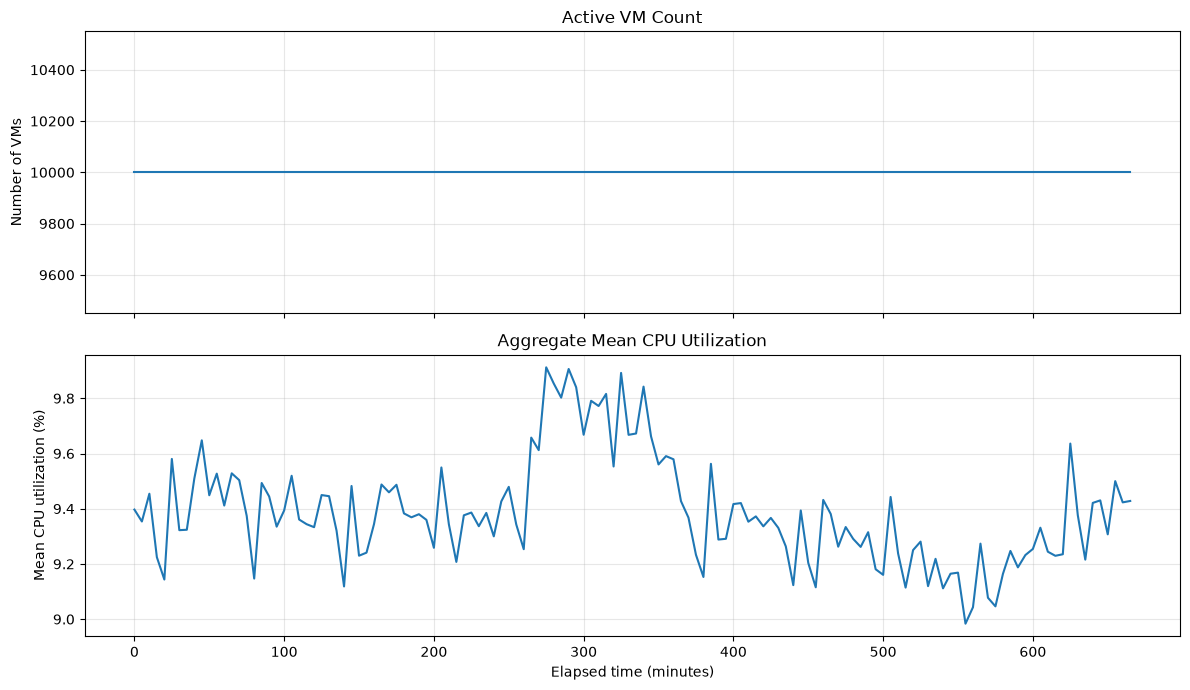

In [25]:
fig, axes = plt.subplots(2, 1, figsize=(12, 7), sharex=True)

axes[0].plot(
    aggregate["timestamp"] / 60,
    aggregate["active_vm_count"],
)
axes[0].set_title("Active VM Count")
axes[0].set_ylabel("Number of VMs")
axes[0].grid(True, alpha=0.3)

axes[1].plot(
    aggregate["timestamp"] / 60,
    aggregate["aggregate_cpu_utilization"],
)
axes[1].set_title("Aggregate Mean CPU Utilization")
axes[1].set_xlabel("Elapsed time (minutes)")
axes[1].set_ylabel("Mean CPU utilization (%)")
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [ ]:
print("Active VM count: unique values")
print(aggregate["active_vm_count"].nunique())

print("\nAggregate CPU utilization:")
print("Minimum:", aggregate["aggregate_cpu_utilization"].min())
print("Maximum:", aggregate["aggregate_cpu_utilization"].max())
print("Standard deviation:", aggregate["aggregate_cpu_utilization"].std())

print("\nLargest absolute five-minute changes:")
print(
    aggregate["aggregate_cpu_utilization"]
    .diff()
    .abs()
    .nlargest(10)
)

Active VM count: unique values
1

Aggregate CPU utilization:
Minimum: 8.98361345296067
Maximum: 9.912175173984915
Standard deviation: 0.1949868647596783

Largest absolute five-minute changes:
5      0.436831
77     0.409914
53     0.404216
125    0.400883
29     0.363877
17     0.346122
65     0.338926
92     0.316503
55     0.299924
41     0.291070
Name: aggregate_cpu_utilization, dtype: float64


: 